In [5]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
from utils import *

In [3]:
import warnings

def fxn():
    warnings.warn("deprecated", RuntimeWarning)
with warnings.catch_warnings(action="ignore"):
    fxn()

In [4]:
d, n = 50 , 10000
X = np.random.randn( n, d )
y = ( np.sum( X , axis = 1 ) <= 0.5 ).astype(np.int64)

In [ ]:
classifier = Binary_classifier(0.01 , 5000 , lam = 0.0 ,  batch_size = 256)
classifier.fit(X,y)

Epochs 1 | Loss 0.6368 | Accuracy 96.54 %
Epochs 101 | Loss 0.4371 | Accuracy 97.85 %
Epochs 201 | Loss 0.4371 | Accuracy 97.81 %
Epochs 301 | Loss 0.4371 | Accuracy 97.87 %
Epochs 401 | Loss 0.4371 | Accuracy 97.84 %
Epochs 501 | Loss 0.4371 | Accuracy 97.90 %
Epochs 601 | Loss 0.4371 | Accuracy 97.87 %
Epochs 701 | Loss 0.4371 | Accuracy 97.82 %
Epochs 801 | Loss 0.4371 | Accuracy 97.84 %
Epochs 901 | Loss 0.4371 | Accuracy 97.93 %
Epochs 1001 | Loss 0.4371 | Accuracy 97.78 %
Epochs 1101 | Loss 0.4371 | Accuracy 97.98 %
Epochs 1201 | Loss 0.4371 | Accuracy 97.92 %
Epochs 1301 | Loss 0.4371 | Accuracy 97.81 %
Epochs 1401 | Loss 0.4371 | Accuracy 97.83 %
Epochs 1501 | Loss 0.4371 | Accuracy 97.82 %
Epochs 1601 | Loss 0.4371 | Accuracy 97.94 %
Epochs 1701 | Loss 0.4371 | Accuracy 97.86 %
Epochs 1801 | Loss 0.4371 | Accuracy 97.89 %
Epochs 1901 | Loss 0.4371 | Accuracy 97.89 %
Epochs 2001 | Loss 0.4371 | Accuracy 97.77 %
Epochs 2101 | Loss 0.4371 | Accuracy 97.85 %
Epochs 2201 | Loss 0.4

In [8]:
# Caricamento del dataset
train = MNIST(root="./data", train=True, download=True)
test = MNIST(root="./data", train=False, download=True)

# Conversione in NumPy e normalizzazione
X_train = train.data.numpy().astype(np.float32) / 255.0
X_test = test.data.numpy().astype(np.float32) / 255.0

# 0 = cifra <= 5, 1 = cifra > 5
y_train = (train.targets.numpy() > 5).astype(np.int64)
y_test = (test.targets.numpy() > 5).astype(np.int64)

# Flatten delle immagini
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

In [ ]:
classifier = Binary_classifier( 0.05 , 5000 , lam = 0.0, batch_size=256 )

idx = np.random.choice( np.arange( X_train.shape[0] ) , size = 5000 , replace=False )
classifier.fit( X_train[idx,:] , y_train[idx] )

Epochs 1 | Loss 0.5461 | Accuracy 75.70 %
Epochs 101 | Loss 0.3652 | Accuracy 87.10 %
Epochs 201 | Loss 0.3633 | Accuracy 87.30 %
Epochs 301 | Loss 0.3624 | Accuracy 87.48 %
Epochs 401 | Loss 0.3620 | Accuracy 87.74 %
Epochs 501 | Loss 0.3618 | Accuracy 87.64 %
Epochs 601 | Loss 0.3621 | Accuracy 87.68 %
Epochs 701 | Loss 0.3619 | Accuracy 87.52 %
Epochs 801 | Loss 0.3623 | Accuracy 87.52 %
Epochs 901 | Loss 0.3620 | Accuracy 87.50 %
Epochs 1001 | Loss 0.3625 | Accuracy 87.46 %
Epochs 1101 | Loss 0.3620 | Accuracy 87.64 %
Epochs 1201 | Loss 0.3621 | Accuracy 87.58 %
Epochs 1301 | Loss 0.3619 | Accuracy 87.68 %
Epochs 1401 | Loss 0.3618 | Accuracy 87.58 %
Epochs 1501 | Loss 0.3618 | Accuracy 87.58 %
Epochs 1601 | Loss 0.3620 | Accuracy 87.74 %
Epochs 1701 | Loss 0.3624 | Accuracy 87.58 %
Epochs 1801 | Loss 0.3619 | Accuracy 87.66 %
Epochs 1901 | Loss 0.3618 | Accuracy 87.60 %
Epochs 2001 | Loss 0.3618 | Accuracy 87.58 %
Epochs 2101 | Loss 0.3618 | Accuracy 87.62 %
Epochs 2201 | Loss 0.3

KeyboardInterrupt: 

In [ ]:
y_test_pred = classifier.classify(X_test)
test_accuracy = 100 * classifier.accuracy(y_test,y_test_pred)
print(f'Test accuracy: {test_accuracy:.2f} %')

Test accuracy: 86.22 %


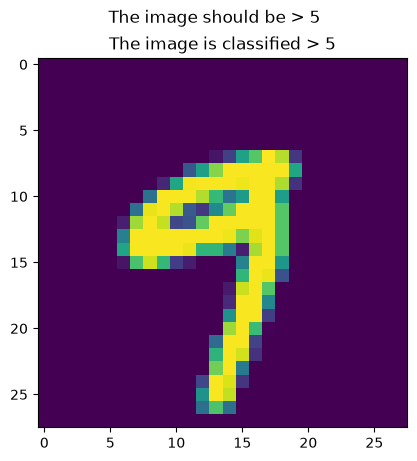

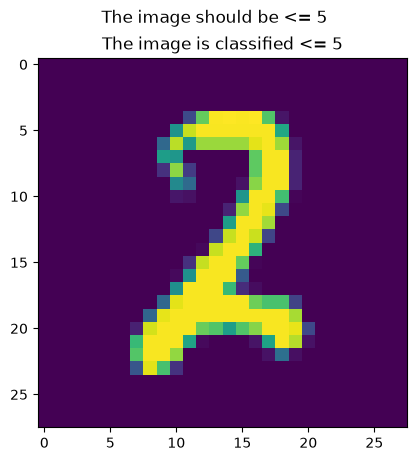

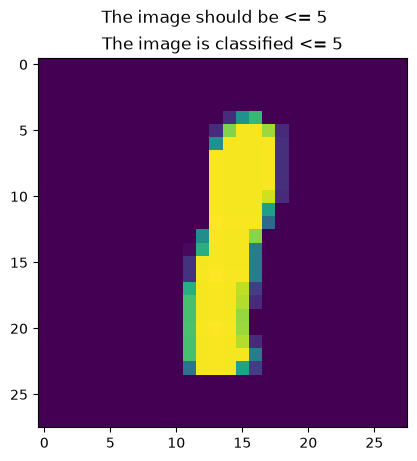

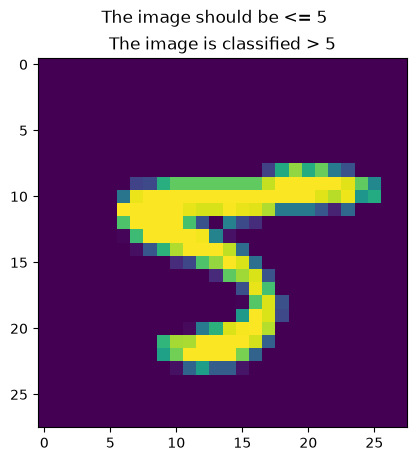

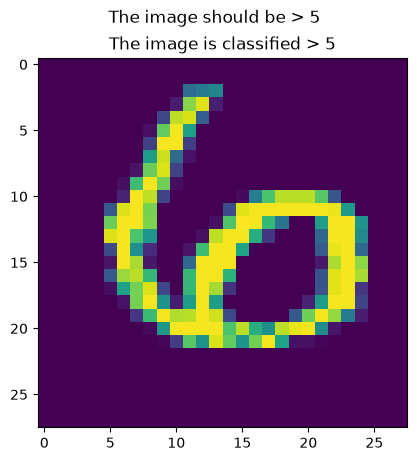

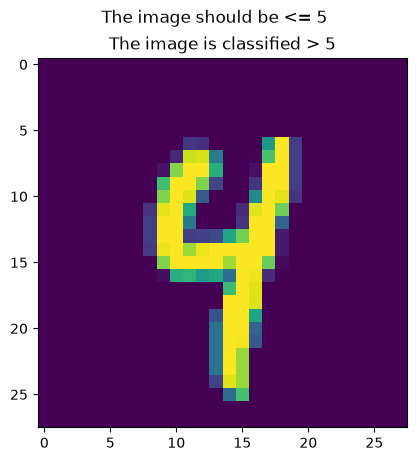

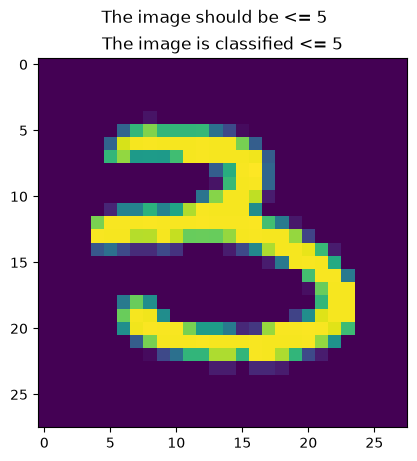

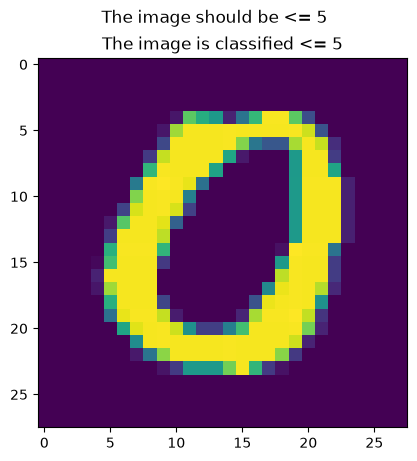

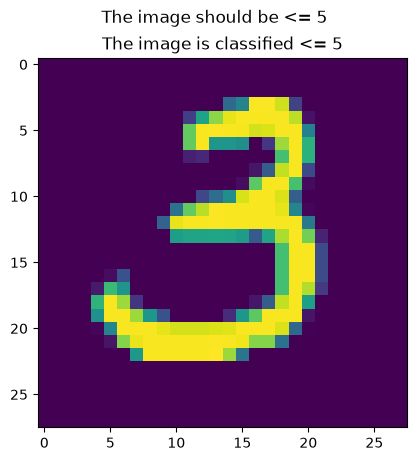

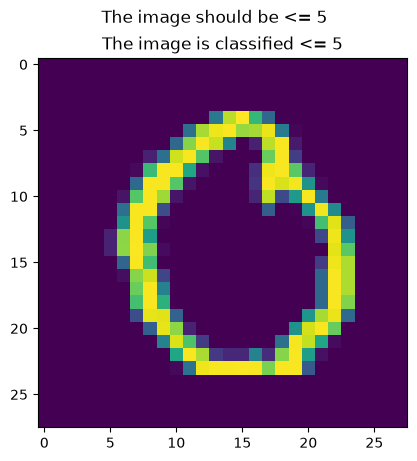

In [ ]:
classif = { 0.: '<= 5', 1.:'> 5' }
for k in np.random.choice( np.arange(5000) , size = 10 , replace=False):
    x_plot = X_test[k,:].reshape(28,-1)
    plt.imshow(x_plot)
    plt.suptitle(f'The image should be {classif[ y_test[k] ]}')
    plt.title(f'The image is classified {classif[ y_test_pred[k] ]}')
    plt.show()